<a href="https://colab.research.google.com/github/Nicolas-Bernal/Simulacion-Estadistica/blob/main/Series%20De%20Tiempo/00-Series_De_TiemporPalma_de_Cera_del_Quind%C3%ADo_(Ceroxylon_quindiuense)_en_Colombia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Nicolas Alexander Bernal Rubio

# Análisis de Series de Tiempo de la Palma de Cera del Quindío (Ceroxylon quindiuense) en Colombia

Se obtuvieron los registros oficiales de presencia de la especie a través de la plataforma global de biodiversidad GBIF (Global Biodiversity Information Facility), garantizando la trazabilidad científica de la información.

GBIF.org (14 de octubre de 2026). GBIF Occurrence Download. https://doi.org/10.15468/dl.0027167-260928105237408

In [ ]:
library(readr)
library(dplyr)

In [ ]:
ruta = "/content/drive/MyDrive/Simulacion Estadistica/segundo corte/Series de Tiempo/0027167-260928105237408.csv"
datos = read_delim(ruta, delim = "\t", escape_double = FALSE, trim_ws = TRUE)

Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”
Rows: 7008 Columns: 50
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr  (33): datasetKey, occurrenceID, kingdom, phylum, class, order, family, ...
dbl  (10): gbifID, individualCount, decimalLatitude, decimalLongitude, coord...
lgl   (5): infraspecificEpithet, coordinatePrecision, depth, depthAccuracy, ...
dttm  (2): dateIdentified, lastInterpreted

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Series De Tiempo Por Año

In [ ]:
head(names(datos))

[1] "gbifID"       "datasetKey"   "occurrenceID" "kingdom"      "phylum"      
[6] "class"

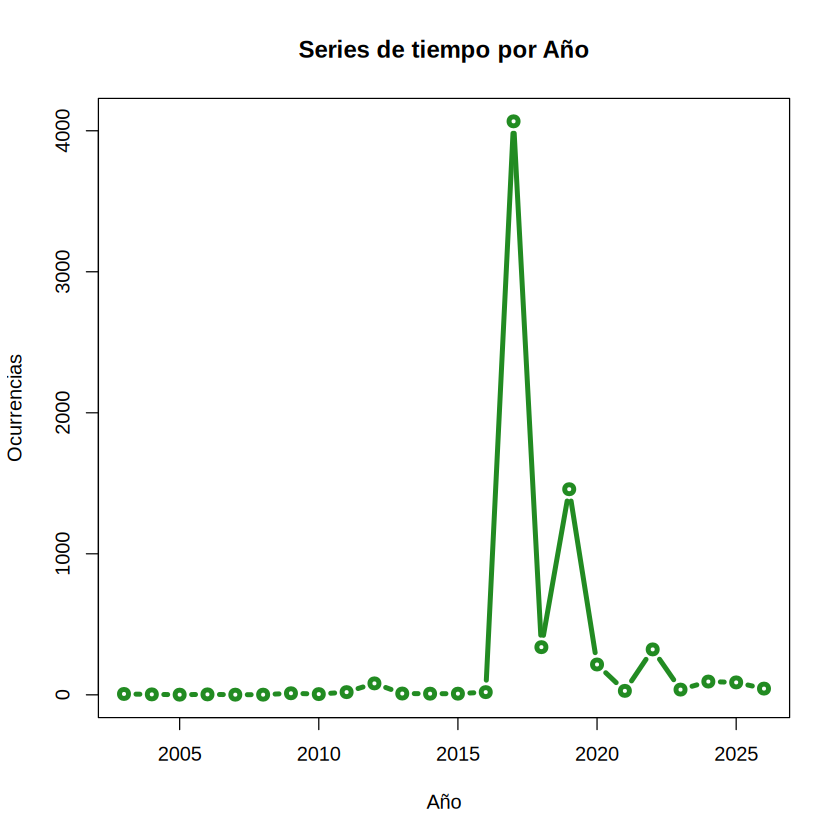

In [ ]:
# conteo de registros por año

serie_año = datos %>%
  filter(!is.na(year) & year > 2000) %>%
  count(year)%>%
  arrange(year)


plot(serie_año, main = "Series de tiempo por Año",ylab = "Ocurrencias", xlab = "Año", col = "forestgreen", lwd = 4,type = "b")


### Acf

* (year): Se observa barras como una escalera que baja muy lentamente y se salen de las líneas azules punteadas.Lo que significa Que los datos suben de manera constante a lo largo de los años (hay una tendencia clara hacia arriba). Es como si cada año que pasa se acumularan más y más registros sin parar.

* Prácticamente en los demas graficos todas las barras se quedan pequeñas y encerradas dentro de las líneas azules punteadas.Por lo Que fuera de la tendencia principal de los años, los datos no tienen un patrón repetitivo que salte a la vista en esos cruces

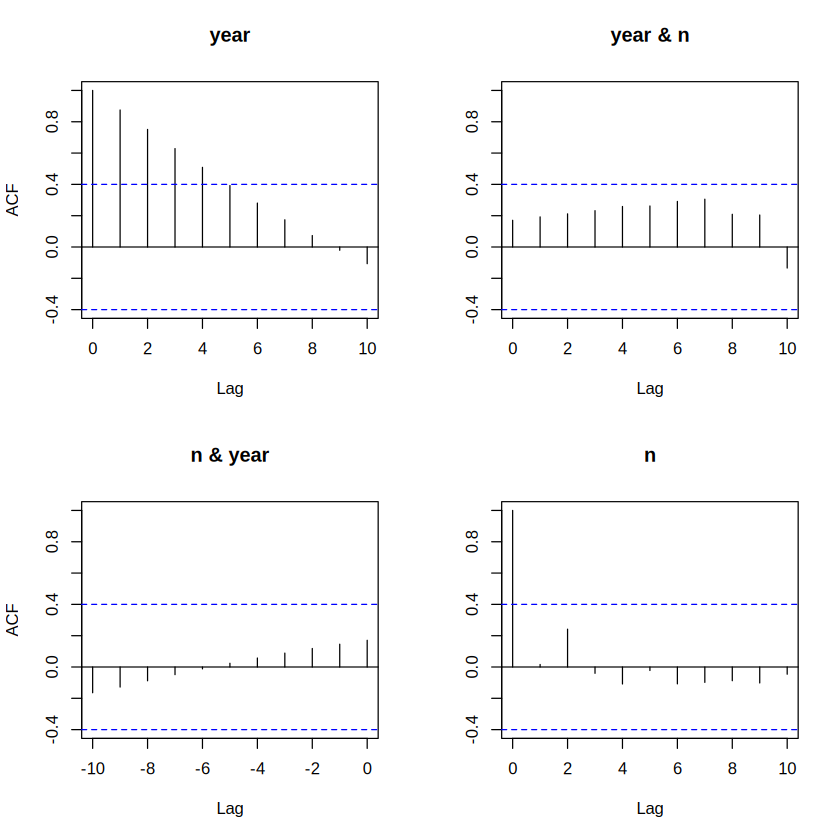

In [ ]:
acf(serie_tiempo)

### Pacf

* en los graficos generales con puntos sobre la linea el cero nos estan confirmando que no existe relacion alguna entre algun dato del pasado que influya en el futuro

* Mientras un grafico muestra unas barras altísimas que rompe por completo la escala vertical. Nos muestra un contraste muy fuerte y directo en el primer rezago (Lag 1), lo que significa que el pasado inmediato (el año anterior) tiene un peso brutal o un impacto directo gigantesco sobre el valor actual.

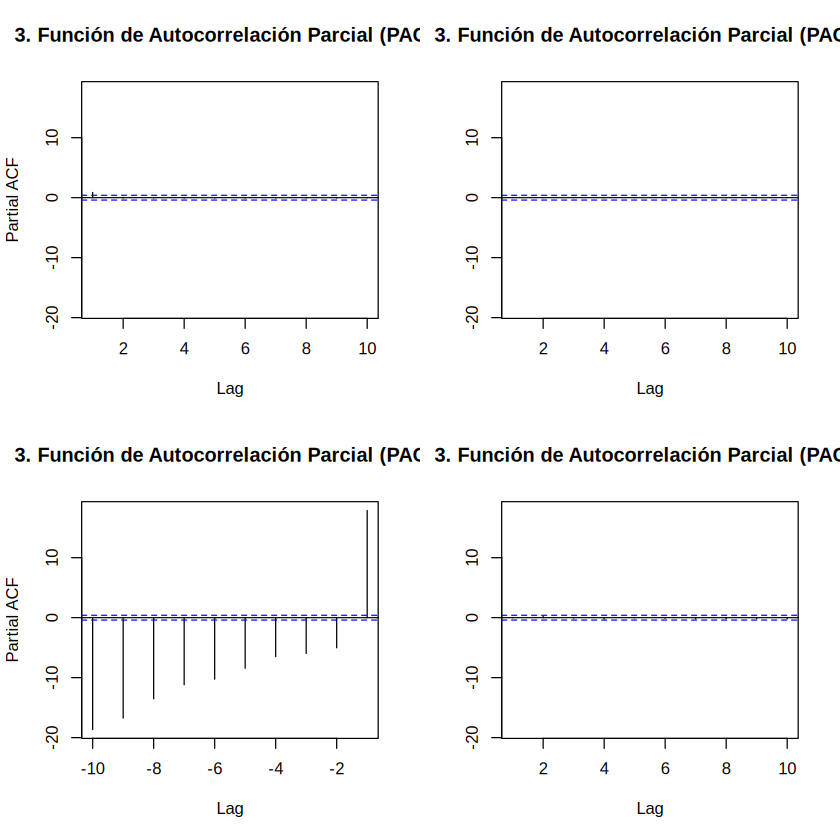

In [ ]:

pacf(serie_tiempo, main = "3. Función de Autocorrelación Parcial (PACF)")

## Series De Tiempo Por Mes

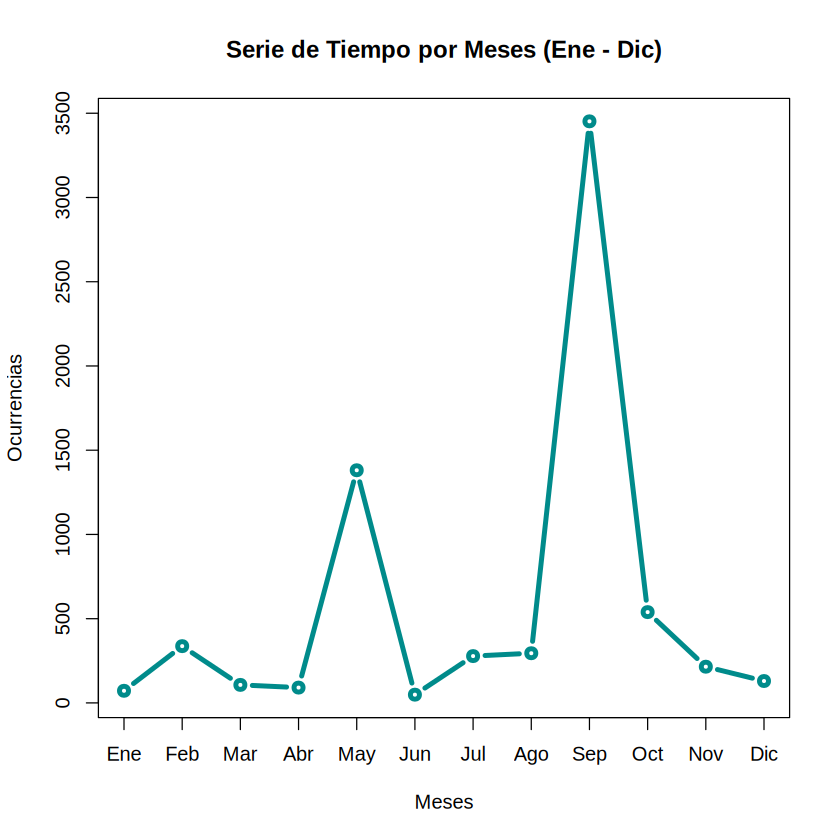

In [ ]:
serie_mes = datos %>%
  filter(!is.na(month) & month >= 1 & month <= 12) %>%
  count(month) %>%
  arrange(month)

plot(serie_mes, main = "Serie de Tiempo por Meses (Ene - Dic)",
    ylab = "Ocurrencias", xlab = "Meses", col = "darkcyan", lwd = 4, xaxt = "n",type = "b")

axis(1, at = 1:12, labels = c("Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"))

### acf

* La primera grafica se ve una barrita gigante al inicio y luego unas barras que van bajando en forma de rampa o escalerita (tocando casi la línea azul punteada).Al igual que pasaba con los años, mes a mes los datos muestran una clara tendencia acumulativa. Los meses cercanos están muy conectados entre sí porque los registros históricos de la palma de cera siguen sumándose con el paso del tiempo

* Las demas graficas Muestran barras cortitas que se quedan mayormente quietas y bien encerradas dentro de los límites de confianza (las líneas azules).Nos indica que no hay sorpresas ocultas de correlaciones cruzadas extremas en esos rezagos específicos.

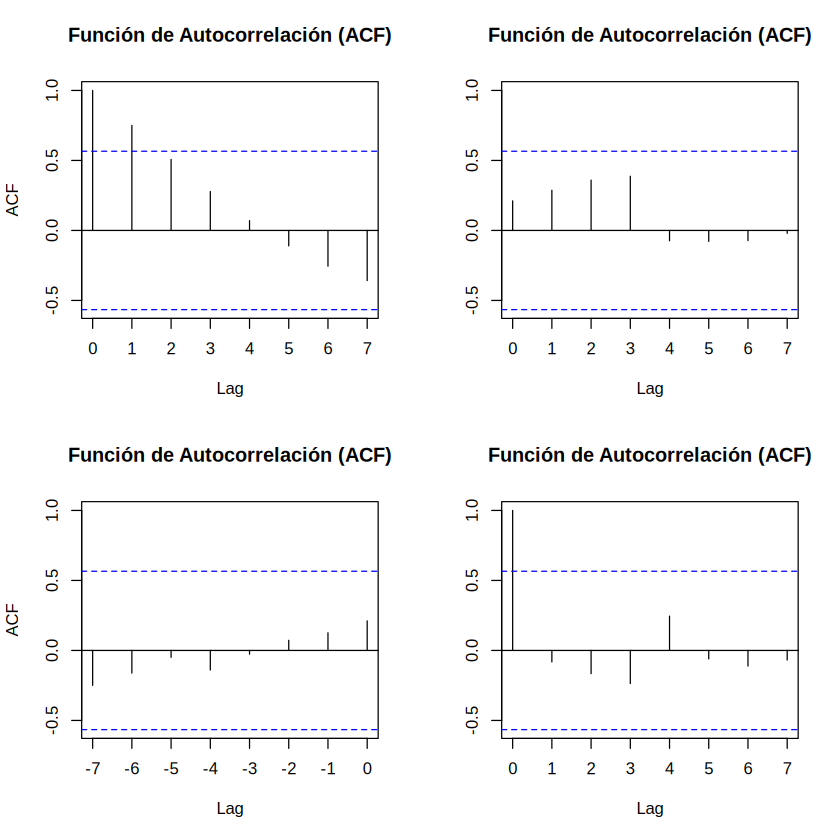

In [ ]:
acf(serie_mes, main = "Función de Autocorrelación (ACF)")

### Pacf

* Se ven completamente horizontales, pegadas a la línea del cero absoluto. Al igual que en los gráficos anteriores, demuestran que la gran mayoría de las relaciones cruzadas o rezagos específicos se mantienen sin efecto o "apagados" una vez se aísla el comportamiento principal.

* El grafico con barras largas muestra barras verticales muy marcadas que se extienden con fuerza hacia abajo (especialmente en los rezagos más lejanos como el -7 y -5) y algunas pequeñas alzas. Refleja que al mirar los datos mes a mes de manera parcializada, existen puntos específicos en el pasado (meses anteriores clave) que ejercen un coletazo o influencia directa sobre el valor actual, mostrando una memoria estacional o un ajuste propio de los ciclos temporales de los reportes

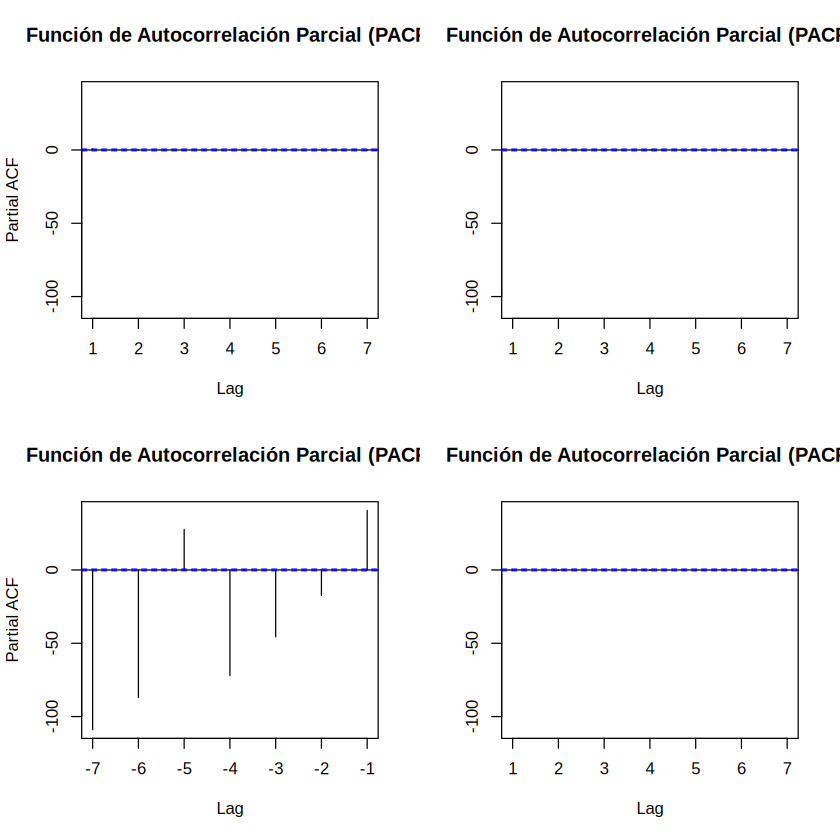

In [ ]:
pacf(serie_mes,main = "Función de Autocorrelación Parcial (PACF)")